# Netflix Shows — Exploratory Data Analysis

**Goal:** understand Netflix's content library: the mix of movies and TV shows, the most common genres, countries, directors and cast, how content was added over time, and how release year, date added, rating and duration relate.

**Dataset:** Netflix Movies and TV Shows (`netflix_titles.csv`, the Kaggle *shivamb/netflix-shows* data; the copy used here is the 2021 release with 7,787 titles).

**Tools:** pandas, NumPy, Matplotlib, Seaborn.

## 1. Setup and loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (10, 5)
pd.set_option('display.max_columns', 20)

df = pd.read_csv('data/netflix_titles.csv')
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,TV Show,3%,NaN,"João Miguel, Bianca Comparato, Michel Gomes, R...",Brazil,"August 14, 2020",2020,TV-MA,4 Seasons,"International TV Shows, TV Dramas, TV Sci-Fi &...",In a future where the elite inhabit an island ...
1,s2,Movie,7:19,Jorge Michel Grau,"Demián Bichir, Héctor Bonilla, Oscar Serrano, ...",Mexico,"December 23, 2016",2016,TV-MA,93 min,"Dramas, International Movies",After a devastating earthquake hits Mexico Cit...
2,s3,Movie,23:59,Gilbert Chan,"Tedd Chan, Stella Chung, Henley Hii, Lawrence ...",Singapore,"December 20, 2018",2011,R,78 min,"Horror Movies, International Movies","When an army recruit is found dead, his fellow..."
3,s4,Movie,9,Shane Acker,"Elijah Wood, John C. Reilly, Jennifer Connelly...",United States,"November 16, 2017",2009,PG-13,80 min,"Action & Adventure, Independent Movies, Sci-Fi...","In a postapocalyptic world, rag-doll robots hi..."
4,s5,Movie,21,Robert Luketic,"Jim Sturgess, Kevin Spacey, Kate Bosworth, Aar...",United States,"January 1, 2020",2008,PG-13,123 min,Dramas,A brilliant group of students become card-coun...


In [2]:
df.shape

(7787, 12)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7787 entries, 0 to 7786
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       7787 non-null   object
 1   type          7787 non-null   object
 2   title         7787 non-null   object
 3   director      5398 non-null   object
 4   cast          7069 non-null   object
 5   country       7280 non-null   object
 6   date_added    7777 non-null   object
 7   release_year  7787 non-null   int64 
 8   rating        7780 non-null   object
 9   duration      7787 non-null   object
 10  listed_in     7787 non-null   object
 11  description   7787 non-null   object
dtypes: int64(1), object(11)
memory usage: 730.2+ KB


## 2. Data cleaning
### 2.1 Missing values

In [4]:
missing = df.isna().sum().to_frame('missing')
missing['percent'] = (missing['missing'] / len(df) * 100).round(2)
missing.sort_values('missing', ascending=False)

,missing,percent
director,2389,30.68
cast,718,9.22
country,507,6.51
date_added,10,0.13
rating,7,0.09
show_id,0,0.00
type,0,0.00
title,0,0.00
release_year,0,0.00
duration,0,0.00


`director`, `cast` and `country` have many gaps. They are text fields we only use for counting, so we fill them with `'Unknown'` rather than dropping ~30% of the titles. Rows missing `date_added` or `rating` are very few and are handled where those columns are used.

In [5]:
for col in ['director', 'cast', 'country']:
    df[col] = df[col].fillna('Unknown')
df['rating'] = df['rating'].fillna('Not Rated')
df.isna().sum()

show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      10
release_year     0
rating           0
duration         0
listed_in        0
description      0
dtype: int64

### 2.2 Duplicates

In [6]:
print('Exact duplicate rows:', df.duplicated().sum())
print('Duplicate show_id:', df['show_id'].duplicated().sum())
print('Same title + type + release year:', df.duplicated(['title', 'type', 'release_year']).sum())

Exact duplicate rows: 0
Duplicate show_id: 0
Same title + type + release year: 0


### 2.3 Data types
`date_added` is text such as *"August 14, 2020"*; we convert it to a datetime. `duration` mixes minutes (movies) and seasons (TV shows), so we split it into a number and a unit.

In [7]:
df['date_added'] = pd.to_datetime(df['date_added'].str.strip(), format='%B %d, %Y', errors='coerce')
df['year_added'] = df['date_added'].dt.year
df['month_added'] = df['date_added'].dt.month

df['duration_value'] = df['duration'].str.extract(r'(\d+)').astype(float)
df['duration_unit'] = np.where(df['duration'].str.contains('Season', na=False), 'seasons', 'min')

# Years between original release and arrival on Netflix
df['age_when_added'] = df['year_added'] - df['release_year']

df[['date_added', 'year_added', 'duration', 'duration_value', 'duration_unit', 'age_when_added']].head()

,date_added,year_added,duration,duration_value,duration_unit,age_when_added
0,2020-08-14,2020.0,4 Seasons,4.0,seasons,0.0
1,2016-12-23,2016.0,93 min,93.0,min,0.0
2,2018-12-20,2018.0,78 min,78.0,min,7.0
3,2017-11-16,2017.0,80 min,80.0,min,8.0
4,2020-01-01,2020.0,123 min,123.0,min,12.0


In [8]:
print('Unparsed dates:', df['date_added'].isna().sum())
print('Negative ages (added before release):', (df['age_when_added'] < 0).sum())
df.dtypes

Unparsed dates: 10
Negative ages (added before release): 12


show_id                   object
type                      object
title                     object
director                  object
cast                      object
country                   object
date_added        datetime64[ns]
release_year               int64
rating                    object
duration                  object
listed_in                 object
description               object
year_added               float64
month_added              float64
duration_value           float64
duration_unit             object
age_when_added           float64
dtype: object

## 3. Descriptive statistics

In [9]:
df[['release_year', 'year_added', 'duration_value', 'age_when_added']].describe().round(2)

,release_year,year_added,duration_value,age_when_added
count,7787.00,7777.00,7787.00,7777.00
mean,2013.93,2018.49,69.12,4.56
std,8.76,1.39,50.95,8.73
min,1925.00,2008.00,1.00,-3.00
25%,2013.00,2018.00,2.00,0.00
50%,2017.00,2019.00,88.00,1.00
75%,2018.00,2020.00,106.00,5.00
max,2021.00,2021.00,312.00,93.00


In [10]:
movies = df[df['type'] == 'Movie']
shows = df[df['type'] == 'TV Show']
print(f"Movie length: mean {movies['duration_value'].mean():.1f} min, median {movies['duration_value'].median():.0f} min, std {np.std(movies['duration_value']):.1f}")
print(f"TV show seasons: mean {shows['duration_value'].mean():.2f}, median {shows['duration_value'].median():.0f}, share with 1 season {np.mean(shows['duration_value'] == 1):.1%}")

Movie length: mean 99.3 min, median 98 min, std 28.5
TV show seasons: mean 1.78, median 1, share with 1 season 66.7%


## 4. Movies vs TV shows

         count  percent
type                   
Movie     5377     69.1
TV Show   2410     30.9


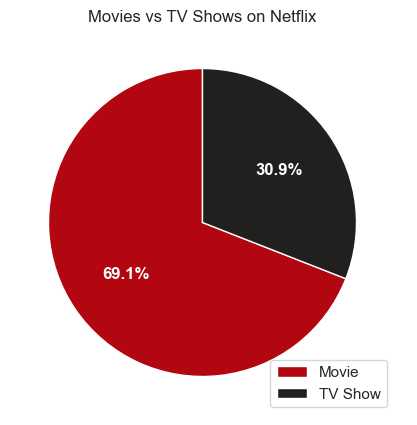

In [11]:
type_counts = df['type'].value_counts()
type_pct = (type_counts / len(df) * 100).round(1)
print(pd.concat([type_counts, type_pct], axis=1, keys=['count', 'percent']))

fig, ax = plt.subplots(figsize=(5, 5))
ax.pie(type_counts, labels=type_counts.index, autopct='%1.1f%%', startangle=90, colors=['#b20710', '#221f1f'],
       textprops={'color': 'white', 'weight': 'bold'})
ax.legend(type_counts.index, loc='lower right')
ax.set_title('Movies vs TV Shows on Netflix')
plt.show()

## 5. Genres, countries, directors and cast
These columns hold comma-separated lists, so we split and *explode* them to count each value.

In [12]:
def explode_counts(series, top=10, exclude=('Unknown',)):
    s = series.str.split(',').explode().str.strip()
    s = s[~s.isin(exclude) & (s != '')]
    return s.value_counts().head(top)

top_genres = explode_counts(df['listed_in'], 15)
top_genres

listed_in
International Movies        2437
Dramas                      2106
Comedies                    1471
International TV Shows      1199
Documentaries                786
Action & Adventure           721
TV Dramas                    704
Independent Movies           673
Children & Family Movies     532
Romantic Movies              531
TV Comedies                  525
Thrillers                    491
Crime TV Shows               427
Kids' TV                     414
Docuseries                   353
Name: count, dtype: int64

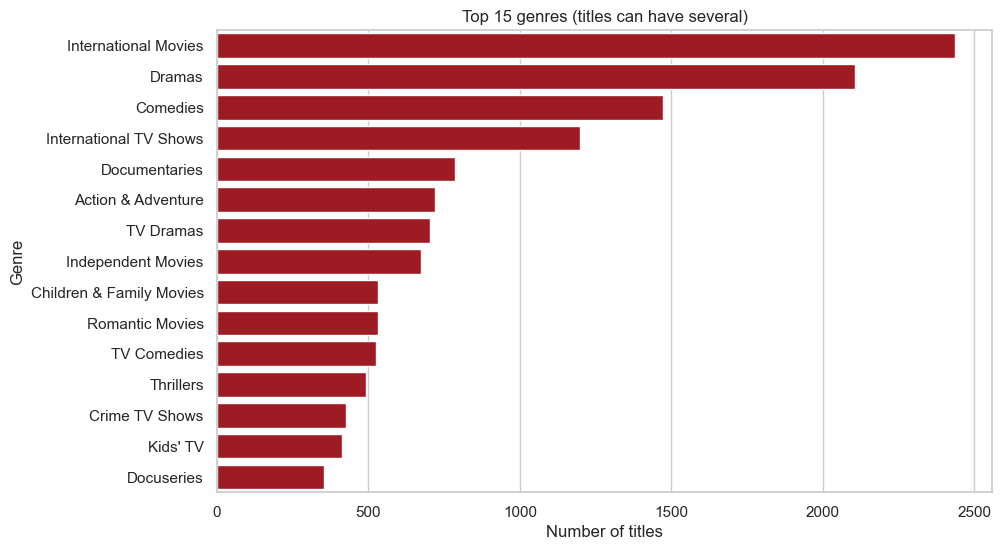

In [13]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=top_genres.values, y=top_genres.index, ax=ax, color='#b20710')
ax.set(title='Top 15 genres (titles can have several)', xlabel='Number of titles', ylabel='Genre')
plt.show()

In [14]:
genre_by_type = pd.concat({
    'Movie': explode_counts(movies['listed_in'], 8),
    'TV Show': explode_counts(shows['listed_in'], 8),
}, axis=1)
genre_by_type

,Movie,TV Show
listed_in,,
International Movies,2437.0,NaN
Dramas,2106.0,NaN
Comedies,1471.0,NaN
Documentaries,786.0,NaN
Action & Adventure,721.0,NaN
Independent Movies,673.0,NaN
Children & Family Movies,532.0,NaN
Romantic Movies,531.0,NaN
International TV Shows,NaN,1199.0


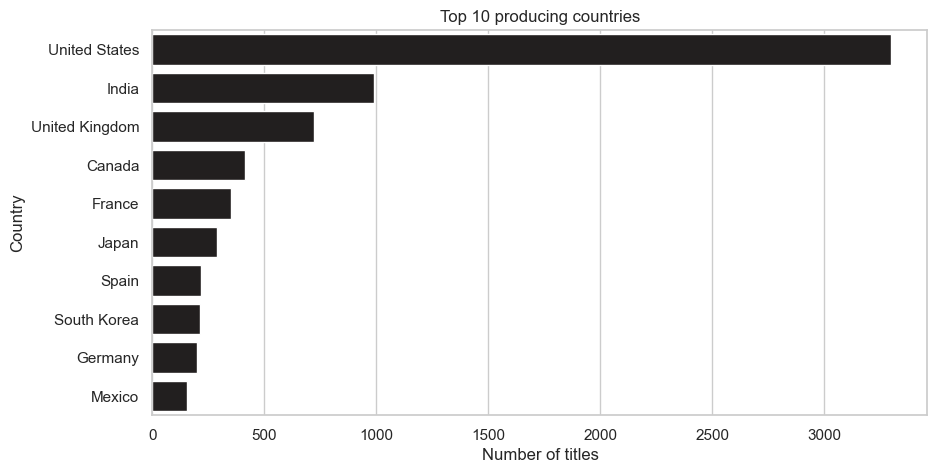

country
United States     3297
India              990
United Kingdom     723
Canada             412
France             349
Japan              287
Spain              215
South Korea        212
Germany            199
Mexico             154
Name: count, dtype: int64

In [15]:
top_countries = explode_counts(df['country'], 10)
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x=top_countries.values, y=top_countries.index, ax=ax, color='#221f1f')
ax.set(title='Top 10 producing countries', xlabel='Number of titles', ylabel='Country')
plt.show()
top_countries

In [16]:
country_type = (df.assign(country=df['country'].str.split(',')).explode('country')
                  .assign(country=lambda d: d['country'].str.strip())
                  .query('country in @top_countries.index')
                  .groupby(['country', 'type']).size().unstack(fill_value=0))
country_type['TV share %'] = (country_type['TV Show'] / country_type.sum(axis=1) * 100).round(1)
country_type.sort_values('Movie', ascending=False)

type,Movie,TV Show,TV share %
country,,,
United States,2431,866,26.3
India,915,75,7.6
United Kingdom,467,256,35.4
Canada,286,126,30.6
France,265,84,24.1
Spain,158,57,26.5
Germany,157,42,21.1
Japan,103,184,64.1
Mexico,101,53,34.4


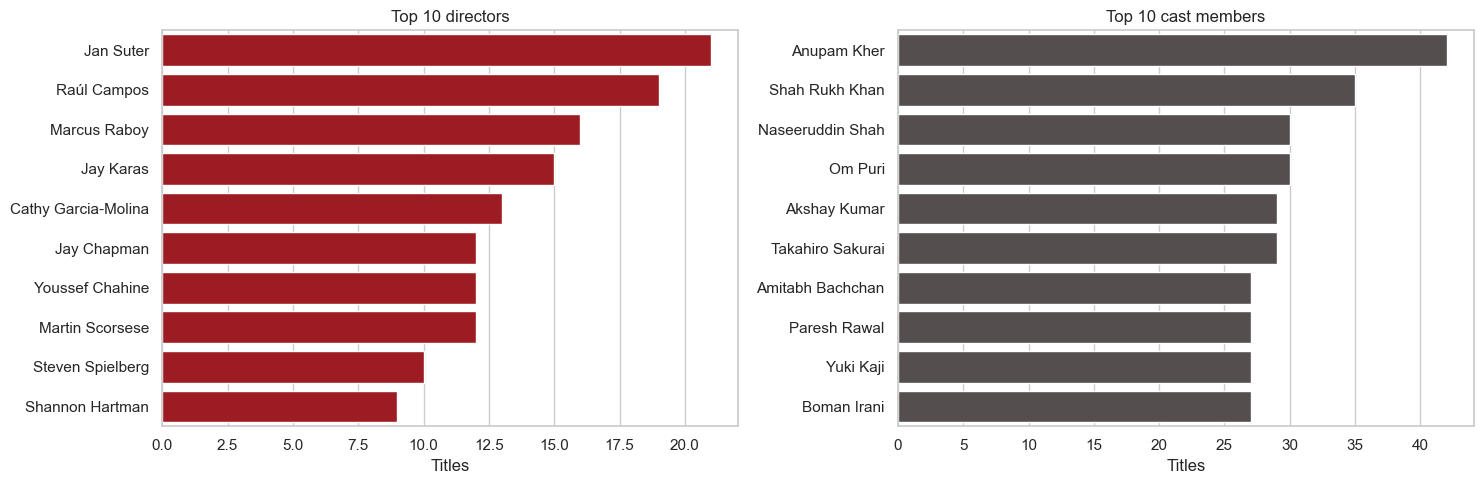

In [17]:
top_directors = explode_counts(df['director'], 10)
top_cast = explode_counts(df['cast'], 10)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(x=top_directors.values, y=top_directors.index, ax=axes[0], color='#b20710')
axes[0].set(title='Top 10 directors', xlabel='Titles', ylabel='')
sns.barplot(x=top_cast.values, y=top_cast.index, ax=axes[1], color='#564d4d')
axes[1].set(title='Top 10 cast members', xlabel='Titles', ylabel='')
plt.tight_layout()
plt.show()

## 6. Content added over time

In [18]:
added = df.dropna(subset=['year_added']).groupby(['year_added', 'type']).size().unstack(fill_value=0)
added.index = added.index.astype(int)
added['Total'] = added.sum(axis=1)
added['YoY growth %'] = (added['Total'].pct_change() * 100).round(1)
added.tail(8)

type,Movie,TV Show,Total,YoY growth %
year_added,,,,
2014,19,6,25,127.3
2015,58,30,88,252.0
2016,258,185,443,403.4
2017,864,361,1225,176.5
2018,1255,430,1685,37.6
2019,1497,656,2153,27.8
2020,1312,697,2009,-6.7
2021,88,29,117,-94.2


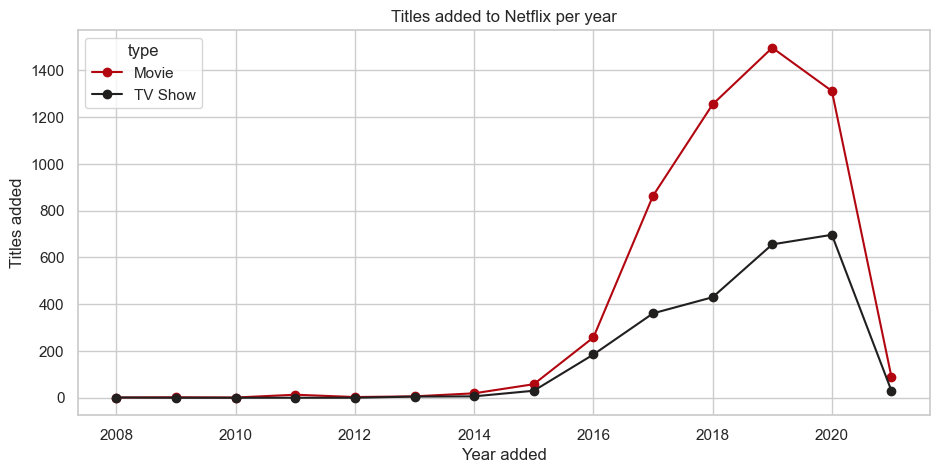

Note: the dataset ends in early 2021, so 2021 is a partial year.
Latest date added: 2021-01-16


In [19]:
fig, ax = plt.subplots(figsize=(11, 5))
added[['Movie', 'TV Show']].loc[2008:].plot(ax=ax, marker='o', color=['#b20710', '#221f1f'])
ax.set(title='Titles added to Netflix per year', xlabel='Year added', ylabel='Titles added')
plt.show()
print('Note: the dataset ends in early 2021, so 2021 is a partial year.')
print('Latest date added:', df['date_added'].max().date())

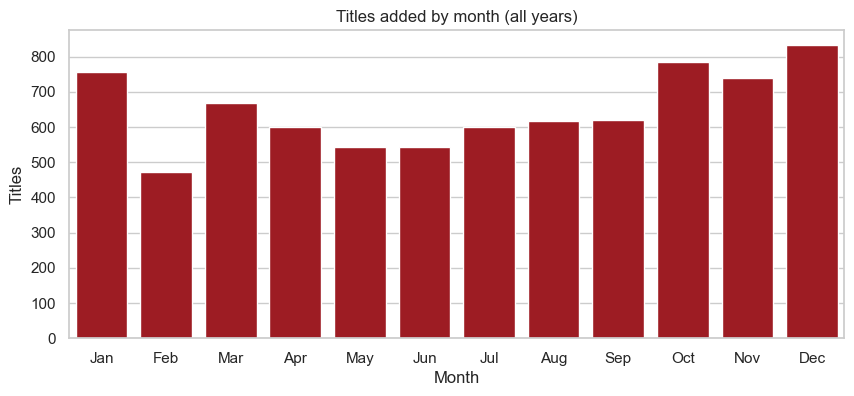

In [20]:
month_counts = df['month_added'].value_counts().sort_index()
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(x=[month_names[int(m) - 1] for m in month_counts.index], y=month_counts.values, ax=ax, color='#b20710')
ax.set(title='Titles added by month (all years)', xlabel='Month', ylabel='Titles')
plt.show()

### Release-year trend

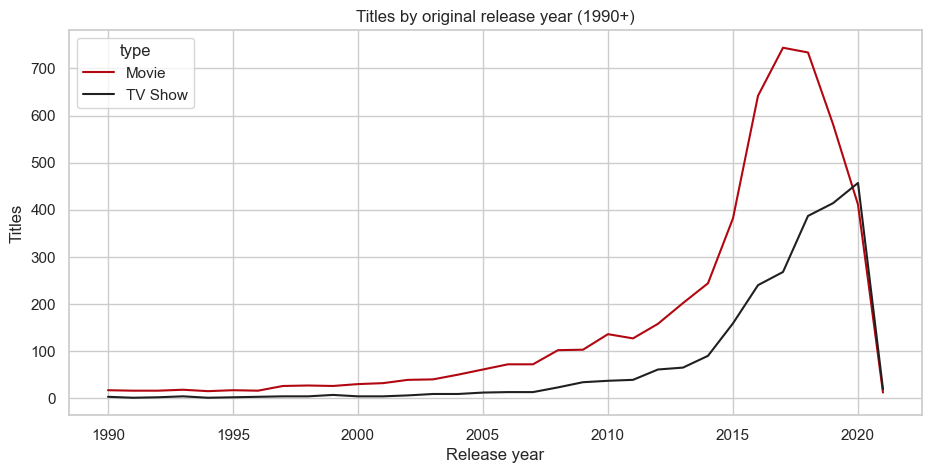

Share of titles released 2015 or later: 70.0%


In [21]:
release = df.groupby(['release_year', 'type']).size().unstack(fill_value=0).loc[1990:]
fig, ax = plt.subplots(figsize=(11, 5))
release.plot(ax=ax, color=['#b20710', '#221f1f'])
ax.set(title='Titles by original release year (1990+)', xlabel='Release year', ylabel='Titles')
plt.show()
print('Share of titles released 2015 or later:', f"{(df['release_year'] >= 2015).mean():.1%}")

## 7. Release year, date added, rating and duration

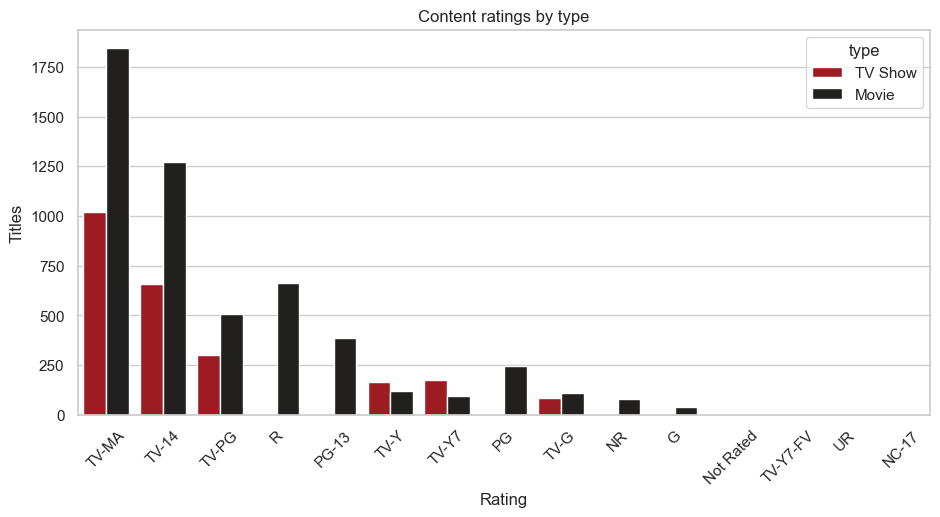

audience
Adults        45.3
Teens         29.8
Older kids    17.1
Kids           6.6
Unrated        1.2
Name: proportion, dtype: float64

In [22]:
rating_counts = df['rating'].value_counts()
fig, ax = plt.subplots(figsize=(11, 5))
sns.countplot(data=df, x='rating', hue='type', order=rating_counts.index, palette=['#b20710', '#221f1f'], ax=ax)
ax.set(title='Content ratings by type', xlabel='Rating', ylabel='Titles')
plt.xticks(rotation=45)
plt.show()

audience = {'TV-MA': 'Adults', 'R': 'Adults', 'NC-17': 'Adults', 'TV-14': 'Teens', 'PG-13': 'Teens',
            'TV-PG': 'Older kids', 'PG': 'Older kids', 'TV-Y7': 'Older kids', 'TV-Y7-FV': 'Older kids',
            'TV-Y': 'Kids', 'TV-G': 'Kids', 'G': 'Kids'}
df['audience'] = df['rating'].map(audience).fillna('Unrated')
(df['audience'].value_counts(normalize=True) * 100).round(1)

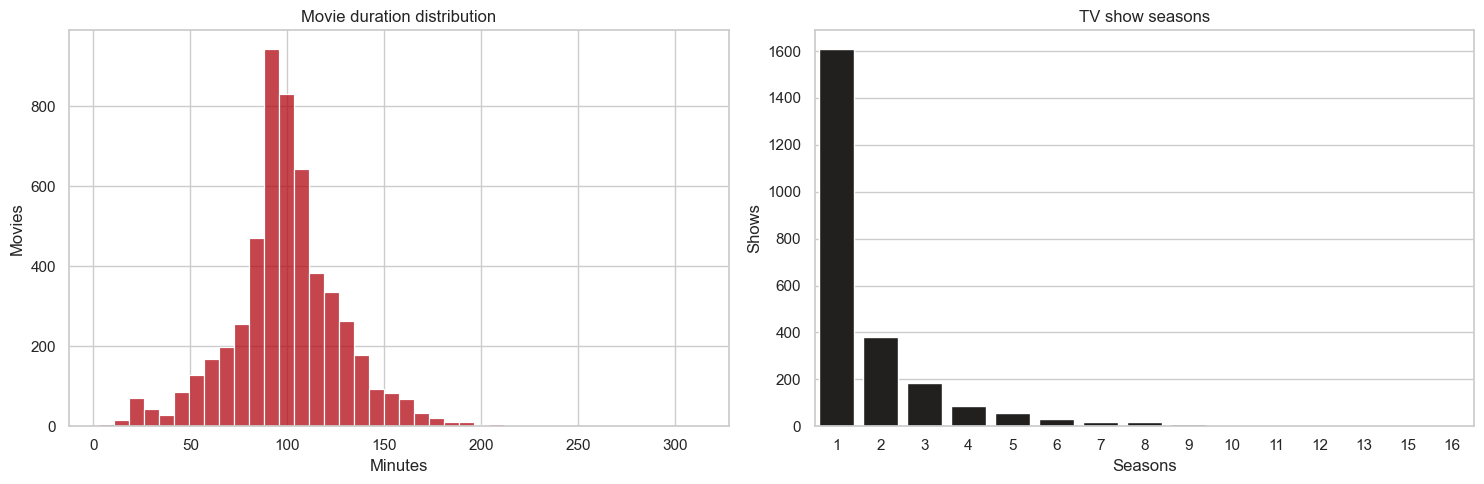

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(movies['duration_value'], bins=40, ax=axes[0], color='#b20710')
axes[0].set(title='Movie duration distribution', xlabel='Minutes', ylabel='Movies')
season_counts = shows['duration_value'].value_counts().sort_index()
sns.barplot(x=season_counts.index.astype(int), y=season_counts.values, ax=axes[1], color='#221f1f')
axes[1].set(title='TV show seasons', xlabel='Seasons', ylabel='Shows')
plt.tight_layout()
plt.show()

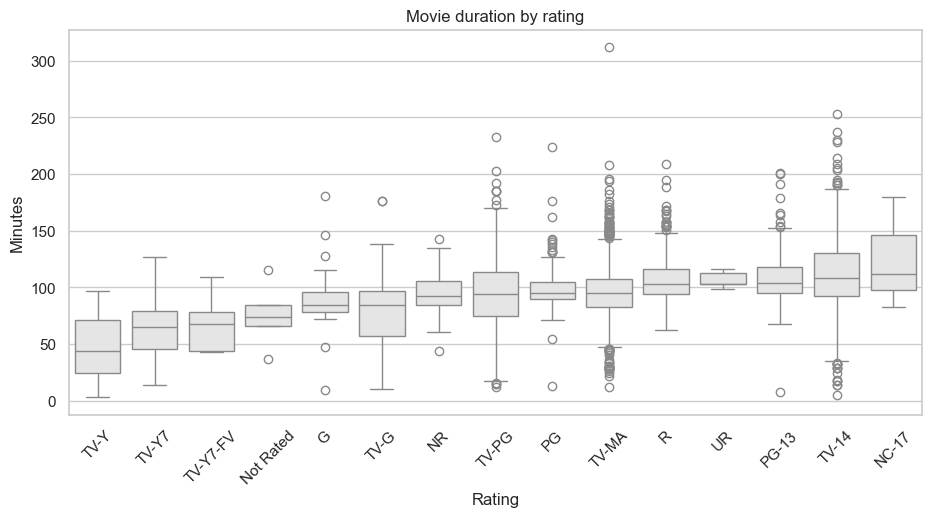

rating
TV-Y          44.0
TV-Y7         65.0
TV-Y7-FV      68.0
Not Rated     74.0
G             84.0
TV-G          84.0
NR            92.0
TV-PG         94.0
PG            95.0
TV-MA         95.0
R            103.0
UR           103.0
PG-13        104.0
TV-14        108.0
NC-17        112.0
Name: duration_value, dtype: float64

In [24]:
fig, ax = plt.subplots(figsize=(11, 5))
order = movies.groupby('rating')['duration_value'].median().sort_values().index
sns.boxplot(data=movies, x='rating', y='duration_value', order=order, ax=ax, color='#e5e5e5')
ax.set(title='Movie duration by rating', xlabel='Rating', ylabel='Minutes')
plt.xticks(rotation=45)
plt.show()
movies.groupby('rating')['duration_value'].median().sort_values()

In [25]:
recent = movies[movies['release_year'] >= 1970]
dur_by_decade = recent.groupby((recent['release_year'] // 10) * 10)['duration_value'].agg(['count', 'mean', 'median']).round(1)
dur_by_decade

,count,mean,median
release_year,,,
1970,63,119.1,112.0
1980,99,116.4,104.0
1990,194,113.9,108.0
2000,601,112.6,108.0
2010,3951,96.8,96.0
2020,423,89.5,94.0


          count  mean  std  min  25%  50%  75%   max
type                                                
Movie    5375.0   5.6  9.7  0.0  0.0  1.0  7.0  75.0
TV Show  2390.0   2.3  5.3  0.0  0.0  0.0  2.0  93.0


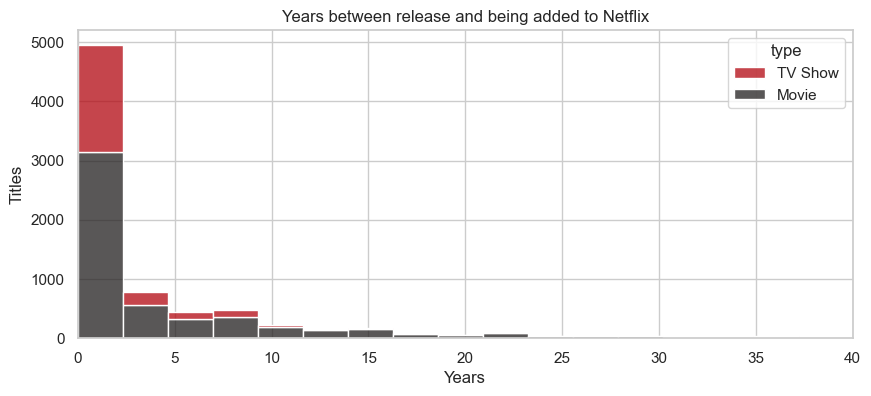

In [26]:
valid = df.dropna(subset=['age_when_added'])
valid = valid[valid['age_when_added'] >= 0]
print(valid.groupby('type')['age_when_added'].describe().round(1))

fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(data=valid, x='age_when_added', hue='type', bins=40, multiple='stack', palette=['#b20710', '#221f1f'], ax=ax)
ax.set(title='Years between release and being added to Netflix', xlabel='Years', ylabel='Titles', xlim=(0, 40))
plt.show()

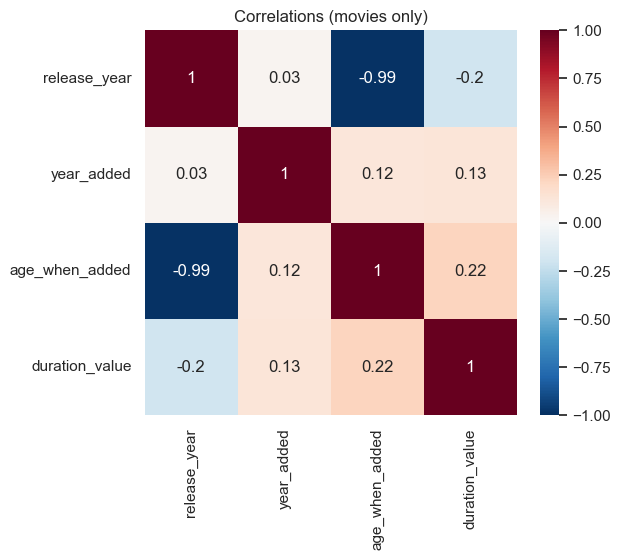

In [27]:
corr_cols = ['release_year', 'year_added', 'age_when_added', 'duration_value']
corr = movies[corr_cols].corr().round(2)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap='RdBu_r', vmin=-1, vmax=1, ax=ax)
ax.set_title('Correlations (movies only)')
plt.show()

## 8. Key insights and conclusions

### Cleaning summary
- Missing values: `director` 30.7%, `cast` 9.2%, `country` 6.5% were filled with "Unknown" (text fields used only for counting). `rating` (7 rows) was filled with "Not Rated". `date_added` (10 rows) was left missing and excluded only from time analysis.
- No duplicate rows, no duplicate `show_id`, and no repeated title + type + year.
- `date_added` converted from text to datetime. `duration` split into a number and a unit (minutes for movies, seasons for TV shows).
- New column `age_when_added` = year added − release year. 12 titles show a negative value (added before their official release year) and were excluded from that analysis.

### Key findings
1. **Library mix:** 5,377 movies (69.1%) and 2,410 TV shows (30.9%).
2. **Genres:**
   - International Movies (2,437), Dramas (2,106) and Comedies (1,471) lead.
   - On the TV side: International TV Shows (1,199), TV Dramas (704) and TV Comedies (525).
   - "International" is the top label for both movies and shows, so non-US content is central to the catalogue.
3. **Countries:**
   - The United States leads (3,297 titles), followed by India (990), the United Kingdom (723), Canada (412) and France (349).
   - Countries specialise differently: India is 92% movies, while South Korea (74%) and Japan (64%) are mostly TV shows (K-dramas and anime).
4. **People:** with director missing for 31% of titles, director counts are incomplete. The top cast list is dominated by Indian actors, which matches India's strong movie catalogue.
5. **Growth over time:**
   - Titles added per year rose from 25 (2014) to 443 (2016), 1,225 (2017) and a peak of 2,153 (2019).
   - 2020 dipped slightly to 2,009 (−6.7%). 2021 holds only two weeks of data.
   - TV-show additions kept rising in 2020 (656 → 697) while movie additions fell (1,497 → 1,312).
6. **Freshness:** 70% of titles were released in 2015 or later. Half of the movies were added within 1 year of release, and half of the TV shows in the same year as release.
7. **Ratings and audience:** about 45% of titles are adult-rated (TV-MA, R, NC-17) and 30% are for teens (TV-14, PG-13). Content for young children (TV-Y, TV-G, G) is only about 7%.
8. **Duration:**
   - The median movie runs 98 minutes, and runtimes have been getting shorter: the median was 112 minutes for 1970s releases and 96 minutes for 2010s releases.
   - Kids' content is much shorter (TV-Y median 44 minutes).
   - Two-thirds of TV shows (66.7%) have only one season.

### Conclusions (content strategy)
- Netflix grew its library fast between 2016 and 2019 and then slowed, which is consistent with a shift from adding volume to focusing on selected content.
- The strategy is clearly global: international movies and shows are the largest genre labels, with Indian movies and Korean/Japanese series as distinct regional strengths.
- The catalogue targets adults and teens. Family and kids' content is a relatively small share, which could be an opportunity.
- Many one-season shows suggest Netflix tests many series and renews few.

### Limitations
- This is a snapshot from January 2021, so it does not show later years.
- Director and cast are missing for a large share of titles.
- Genres are Netflix's own tags, and one title can carry several.
- The patterns above are associations in the catalogue and do not show what caused them.
